<a href="https://colab.research.google.com/github/lamboant01/maie383/blob/main/lab04_student.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MIAE 383: Lab 4

## PCA, clustering and anomalies

Work in pairs on one branch, or individually if needed. Each student runs and writes about their own view. Submit individually during the lab, with the upload allowance until 11:25. Duration: 140 minutes.

**Marks:** code 50, analysis 20, memo 20, individual check 10. The lab is worth 5% of the course.

**Submit:** your executed notebook and results.json, with the memo inside the notebook.

Disclose AI explanation/debugging help. Write your analysis and memo yourself. The micro-quiz is individual and ungraded; no AI or partner help.

## Preparation

Sessions 11-14: k-means, complete linkage, silhouette, PCA and anomaly detection. Run preparation.ipynb before the lab.

## Branches

**Mechanical:** Hydraulic test-rig cycles: compare pressure/flow regimes, then compare clusters with the recorded cooler and valve conditions after fitting. A cluster or distance score has no automatic fault label. PS1-PS6 are pressure channels (bar); FS1-FS2 are flow channels (L/min). Each cycle supplies a mean and standard deviation for each channel.

**Industrial:** Power plant: group ambient operating conditions and flag unusual ones. Inputs: AT: ambient temperature (°C); V: exhaust vacuum (cm Hg); AP: ambient pressure (mbar); RH: relative humidity (%).

**Aerospace:** Wind-tunnel operating-condition groups and unusual acoustic-test settings; clusters describe the sampled experiment. Inputs: frequency (Hz), angle of attack (degrees), chord length (m), free-stream speed (m/s), and suction-side displacement thickness (m). The last quantity is the column displacement_m.

Variable definitions: [UCI plant data](https://archive.ics.uci.edu/dataset/294/combined+cycle+power+plant) and [UCI airfoil data](https://archive.ics.uci.edu/dataset/291/airfoil+self+noise).

Mechanical uses the same hydraulic rig as Lab 3 Aerospace. Component annotations are inspected after fitting. Industrial and Aerospace have no verified fault labels: investigate unusual conditions. Hydraulic variable definitions: [UCI hydraulic data](https://archive.ics.uci.edu/dataset/447/condition+monitoring+of+hydraulic+systems).

## PCA, clustering and anomaly scores

Fit imputation, scaling and two-component PCA on training data. PCA retains directions of high variance; k-means minimizes within-cluster squared distance.

- Compare K = 2, 3, 4.
- Use K = 3 for the shared anomaly calculation.
- Score each record by its distance to the nearest centroid in PCA coordinates.
- Flag test scores strictly above the validation scores' 95th percentile.

Inspect flagged records in the original measurement units. A statistical flag does not establish a fault.

## Work plan

| Time | Task |
| --- | --- |
| 08:45-09:00 | Open the kit; enter issued codes and confirm the data |
| 09:00-10:00 | Complete four functions, run their checks and the supplied investigations |
| 10:00-10:45 | Finish the short analysis and individual memo |
| 10:45-10:53 | Micro-quiz (MCQ) |
| 10:53-11:05 | Export, download and verify both submission files |

The allowance to 11:25 is for upload problems. The demonstrator checks individual understanding during the work. If a function still fails after 15 minutes, ask for help and work on a written answer while you wait.

In [1]:
#@title Load supplied libraries and data files
from pathlib import Path
import sys, json, time, zipfile
_expected_lab = 4
_expected_kit_version = 'lab-final-20261017'
_required = ['src/miae383/data.py', 'data/manifest.json', 'data/hydraulic.csv', 'data/powerplant.csv', 'data/airfoil.csv']

def _matching_folder(folder):
    if not all((folder/name).is_file() for name in _required):
        return False
    manifest = folder/'kit_manifest.json'
    if not manifest.exists():
        return True
    metadata = json.loads(manifest.read_text())
    return metadata.get('lab') == _expected_lab and metadata.get('version') == _expected_kit_version

def _matching_archive(path):
    try:
        with zipfile.ZipFile(path) as archive:
            if not set(_required).issubset(archive.namelist()):
                return False
            if 'kit_manifest.json' in archive.namelist():
                metadata = json.loads(archive.read('kit_manifest.json'))
                return metadata.get('lab') == _expected_lab and metadata.get('version') == _expected_kit_version
            return path.name == 'course_support.zip'
    except (zipfile.BadZipFile, KeyError, ValueError):
        return False

_archives = [p for p in Path.cwd().glob('*')
             if p.suffix.lower() == '.zip' and _matching_archive(p)]
_search = [Path.cwd()] if _archives else [Path.cwd(), *Path.cwd().parents]
ROOT = next((p for p in _search if _matching_folder(p)), None)
if ROOT is None:
    if not _archives:
        try:
            from google.colab import files
        except ImportError:
            raise RuntimeError('Extract the current Lab 4 student kit and open its notebook from that folder. See START_HERE.pdf.')
        print('Upload the Lab 4 student ZIP.')
        _uploaded = [Path(name) for name in files.upload() if name.lower().endswith('.zip')]
        if len(_uploaded) != 1 or not _matching_archive(_uploaded[0]):
            raise RuntimeError('Upload the current Lab 4 Student Kit ZIP from Moodle. Older kits and re-zipped folders are not supported.')
        _archives = _uploaded
    if len(_archives) != 1:
        raise RuntimeError('Keep one current Lab 4 support ZIP in this runtime.')
    ROOT = Path.cwd().resolve()
    with zipfile.ZipFile(_archives[0]) as archive:
        if any(not (ROOT/name).resolve().is_relative_to(ROOT) for name in archive.namelist()):
            raise RuntimeError('Invalid ZIP path. Request a fresh kit.')
        # Extract runtime support only; do not create a blank notebook beside results.json.
        for member in archive.namelist():
            if member.startswith(('src/', 'data/', 'labs/')) or member == 'kit_manifest.json':
                archive.extract(member, ROOT)
if 'miae383.data' in sys.modules:
    _loaded = Path(sys.modules['miae383.data'].__file__).resolve()
    if not _loaded.is_relative_to(ROOT.resolve()):
        raise RuntimeError('Restart the runtime, then rerun from this lab folder.')
try:
    import otter
except ModuleNotFoundError:
    if 'google.colab' not in sys.modules:
        raise RuntimeError('Install requirements-local.txt first. See START_HERE.pdf.')
    import subprocess
    subprocess.run([sys.executable,'-m','pip','install','-q','otter-grader==6.1.6'],check=True)
sys.path.insert(0,str(ROOT/'src'))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from miae383.identity import ViewContext, is_preview_identity, check_submission_identity
from miae383.data import assigned_view, split_arrays, model_seed
print('Runtime:',sys.version.split()[0], '| NumPy',np.__version__,
      '| pandas',pd.__version__, '| scikit-learn',sklearn.__version__)
print('Setup complete. Continue to Assigned view.')


Upload the Lab 4 student ZIP.


Saving Lab 4 - Student Kit (1).zip to Lab 4 - Student Kit (1).zip
Runtime: 3.13.18 | NumPy 2.4.6 | pandas 2.2.3 | scikit-learn 1.6.1
Setup complete. Continue to Assigned view.


## Assigned view

Enter the issued details **at the start of the lab, before the investigations**. DEMO is for preparation only.

- **STUDENT_TOKEN:** your four-letter token, not your student number.
- **SECTION_ID:** your registered section. Confirm its release code with the demonstrator.
- **BRANCH:** both partners choose the same branch; each student uses their own data view.
- **RELEASE_CODE:** the four-letter code issued for this lab and section.
- **PAIR_ID:** both partners' tokens, alphabetically joined by a hyphen, for example `ABCD-WXYZ`.

Working alone, or partner not here yet: enter only your own token. Correct the label if a partner joins; your results are kept.

Rerunning this cell with the same data details preserves results. Correcting only the pair label also preserves results. A change of token, section, branch or release code requires saving the notebook, restarting and rerunning before updating the answers.

In [23]:
# Enter issued details before starting the assessed work.
LAB_ID = 4
STUDENT_TOKEN = "KBWC" #@param {type:"string"}
SECTION_ID = "FI" #@param ["", "AI", "BI", "CI", "DI", "FI"]
BRANCH = "industrial" #@param ["mechanical", "industrial", "aerospace"]
# Release code: the section code announced by the demonstrator.
RELEASE_CODE = "JUXH" #@param {type:"string"}
# Pair label: your token alone, or both tokens, for example ABCD-WXYZ.
PAIR_ID = "DTXD-KBWC" #@param {type:"string"}
from miae383.lab_session import load_session
load_session(globals())


Assigned data: section FI; branch industrial; pair DTXD-KBWC.
Confirm your section and release code with the demonstrator.
Source: powerplant
Excluded target/annotation (not used for fitting): net electrical power | units: MW
Split: grouped identical predictor rows; temporal validation unavailable
Records: training=432, validation=144, test=144
Inputs: AT, V, AP, RH
Model seed: 3778007700
Existing investigation results preserved: [1, 2]


## Four functions

Each comment is one small step, usually one or two lines. Complete the function and run its check. If it fails, read the message, correct the function and rerun the check. Keep the names and arguments. Investigations, plots and export are supplied. Hidden grading tests check the same rules on other inputs.

### fit_representation: 15 points

Create and fit a pipeline on X_train only:

1. `SimpleImputer(strategy="median", keep_empty_features=True)`
2. `StandardScaler()`
3. `PCA(n_components=n_components, svd_solver="full")`

Combine these with `make_pipeline` in this order. Return the fitted pipeline; its transform method applies the same representation to validation and test records.

In [7]:
def fit_representation(X_train, n_components):
    # Create a median SimpleImputer with keep_empty_features=True.
    imputer = SimpleImputer(strategy="median", keep_empty_features=True)

    # Create a StandardScaler.
    scaler = StandardScaler()
    # Create PCA with the supplied n_components and svd_solver="full".
    pca = PCA(n_components=n_components, svd_solver="full")
    # Put the imputer, scaler and PCA in one pipeline with make_pipeline, in that order.
    pipeline = make_pipeline(imputer, scaler, pca)
    # Fit the pipeline on X_train only and return the fitted pipeline.
    pipeline.fit(X_train)
    return pipeline

In [8]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab04/public_tests'))
grader.check('fit_representation')


fit_representation results: All test cases passed!

### fit_clusters: 10 points

Fit `KMeans(n_clusters=k, n_init=10, random_state=seed)` on Z_train and return the estimator.

**Return:** a fitted `KMeans` object. Its `labels_` and `inertia_` describe the fitted training rows. Its `predict(Z)` assigns new observations to the stored centroids.

Keep `n_init=10` and the supplied seed for the controlled comparison.

In [9]:
def fit_clusters(Z_train, k, seed):
    # Create KMeans with n_clusters=k, n_init=10 and random_state=seed.
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=seed)
    # Fit the estimator on Z_train and return the fitted estimator.
    kmeans.fit(Z_train)
    return kmeans

In [10]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab04/public_tests'))
grader.check('fit_clusters')


fit_clusters results: All test cases passed!

### anomaly_scores: 15 points

Return one Euclidean distance per observation: the distance to its nearest supplied centroid. Inputs are finite 2D arrays with the same number of features and at least one centroid. Reject incompatible or nonfinite inputs with ValueError.

Check: [3, 4] with centroids [[0, 0], [9, 12]] gives **5**, not 10 or 25. `centres` is the function argument containing the centroids. Input checks are supplied.

In [13]:
def anomaly_scores(Z, centres):
    # Supplied input checks; keep these lines.
    Z = np.asarray(Z, dtype=float)
    centres = np.asarray(centres, dtype=float)
    if Z.ndim != 2 or centres.ndim != 2 or Z.shape[1] != centres.shape[1] or len(centres) == 0:
        raise ValueError("Use 2D arrays with matching features and at least one centroid.")
    if not np.isfinite(Z).all() or not np.isfinite(centres).all():
        raise ValueError("Distances require finite coordinates.")
    # A loop over observations is acceptable; vectorization is not required.
    # 1. Subtract each centroid from the observation and square the differences.
    difference = Z[:, np.newaxis, :] - centres
    squared_differences = difference ** 2
    # 2. Sum over components and take the square root (np.sqrt).
    distances = np.sqrt(squared_differences.sum(axis=2))
    # 3. Keep the smallest distance (np.min); return one per row as a NumPy array.
    return np.min(distances, axis=1)

In [14]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab04/public_tests'))
grader.check('anomaly_scores')


anomaly_scores results: All test cases passed!

### calibrate_threshold: 10 points

Use finite, nonempty 1D scores and a quantile in [0, 1]. Reject invalid input with ValueError.

Return `np.quantile(scores, quantile, method="linear")`. Flagging uses **score > threshold**.

In [19]:
def calibrate_threshold(scores, quantile):
    # Convert scores to a floating-point NumPy array.
    scores = np.asarray(scores, dtype=float)
    # Supplied input checks; keep these lines.
    if scores.ndim != 1 or scores.size == 0 or not np.isfinite(scores).all():
        # Reject a non-1D, empty or nonfinite array with ValueError.
        raise ValueError("Use a 1D array of finite scores.")
    if quantile < 0 or quantile > 1:
        # Reject a quantile outside [0,1], including NaN.
        raise ValueError("Use a quantile in [0, 1].")
    # Return float(np.quantile(scores, quantile, method="linear")).
    return float(np.quantile(scores, quantile, method="linear"))

In [20]:
import otter
grader=otter.Notebook(tests_dir=str(ROOT/'labs/lab04/public_tests'))
grader.check('calibrate_threshold')


calibrate_threshold results: All test cases passed!

## Supplied investigations

Run these cells in order after the four function checks. Edit the labelled response cells. Keep the supplied experiment code and data partitions.

### Investigation 1: Fit the representation on training records

Check the PCA score shapes. Confirm that the fitted pipeline used only training records.

In [21]:
_begin_stage(1)
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import linkage, dendrogram
(Xtr, ytr), (Xva, yva), (Xte, yte) = split_arrays(view)
# Targets and condition annotations are not used to fit this representation.
representation = fit_representation(Xtr, 2)
Ztr = representation.transform(Xtr)
Zva = representation.transform(Xva)
Zte = representation.transform(Xte)
print("PCA shapes (train, validation, test):", Ztr.shape, Zva.shape, Zte.shape)
variance = representation[-1].explained_variance_ratio_
print(f"Retained variance PC1, PC2: {variance[0]:.1%}, {variance[1]:.1%} (total {variance.sum():.1%})")
_finish_stage(1, {"explained_variance": float(variance.sum())})


PCA shapes (train, validation, test): (432, 2) (144, 2) (144, 2)
Retained variance PC1, PC2: 61.7%, 23.9% (total 85.6%)


### Investigation 2: Compare cluster structure

Compare the table and the three plots, all in the same PCA coordinates. Select a descriptive K using the evidence. The following anomaly investigation uses fixed K=3 for comparability.

 k    inertia  silhouette
 2 658.816066    0.473309
 3 475.792817    0.407763
 4 373.594074    0.356942


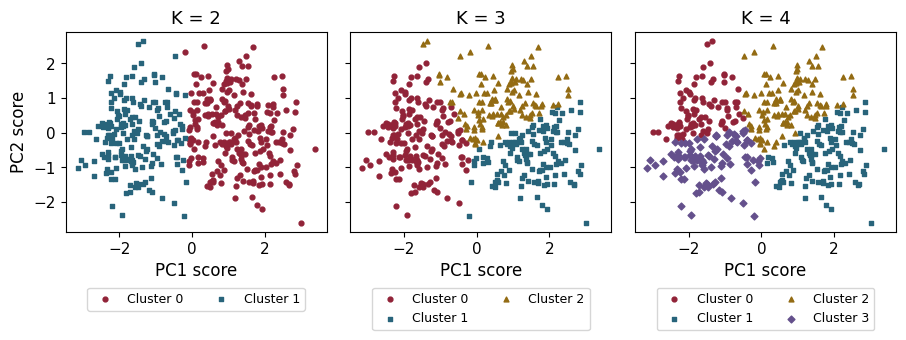

In [22]:
_begin_stage(2)
rows, candidates = [], {}
for k in [2, 3, 4]:
    fitted = fit_clusters(Ztr, k, SEED)
    candidates[k] = fitted
    rows.append({
        "k": k, "inertia": float(fitted.inertia_),
        "silhouette": float(silhouette_score(Ztr, fitted.labels_)),
    })
print(pd.DataFrame(rows).to_string(index=False))

# Show each proposed partition in exactly the same fitted coordinates.
colors = ["#912338", "#28647B", "#936B13", "#64508c"]
markers = ["o", "s", "^", "D"]
fig, axes = plt.subplots(1, 3, figsize=(9.2, 3.7), sharex=True, sharey=True)
for ax, k in zip(axes, [2, 3, 4]):
    for cluster_id in range(k):
        member = candidates[k].labels_ == cluster_id
        ax.scatter(Ztr[member, 0], Ztr[member, 1], s=12,
                   color=colors[cluster_id], marker=markers[cluster_id],
                   label=f"Cluster {cluster_id}")
    ax.set_title(f"K = {k}", fontsize=13)
    ax.set_xlabel("PC1 score", fontsize=12)
    ax.tick_params(labelsize=11)
    ax.legend(fontsize=9, loc="upper center", bbox_to_anchor=(0.5, -0.25), ncol=2)
axes[0].set_ylabel("PC2 score", fontsize=12)
fig.tight_layout()
fig.subplots_adjust(bottom=0.36)
plt.show()
_finish_stage(2, {"cluster_comparison": rows})


## Number of clusters: 6 analysis points

Complete the labelled lines below in at most 60 words. Refer to supplied tables and figures; do not copy them.

**Chosen K:** k=2

**Inertia, silhouette and scatter-plot evidence:** inertia = 658 and the silhouette = 0.47, with 2 well defined clusters.

**Reason for this descriptive choice:** highest silhouette score and simples division.

### Investigation 3: Set the anomaly threshold

The score is nearest-centroid distance in the retained PCA coordinates. The threshold uses validation scores; test scores do not change it.

In [24]:
_begin_stage(3)
# K=3 is fixed for this common anomaly investigation, regardless of your K choice.
clusters = candidates[3]
calibration_scores = anomaly_scores(Zva, clusters.cluster_centers_)
threshold = calibrate_threshold(calibration_scores, 0.95)
print("Validation observations:", len(calibration_scores))
print("95th-percentile threshold (PCA-coordinate distance):", round(float(threshold), 4))
print("Validation scores strictly above it:", int((calibration_scores > threshold).sum()))
_finish_stage(3, {"anomaly_threshold": threshold})


Validation observations: 144
95th-percentile threshold (PCA-coordinate distance): 1.8199
Validation scores strictly above it: 8


### Investigation 4: Apply the same threshold to the test records

Use the strict score > threshold rule. The table identifies the three largest scores, including any that do not exceed the threshold. Zero flags is a valid result; keep the calibrated threshold. A large score alone is not a fault diagnosis.

In [25]:
_begin_stage(4)
test_scores = anomaly_scores(Zte, clusters.cluster_centers_)
flags = test_scores > threshold
test_groups = clusters.predict(Zte)
largest = np.argsort(-test_scores, kind="stable")[:3]
largest_records = pd.DataFrame({
    "record_id": view["record_ids"].iloc[view["test"][largest]].to_numpy(),
    "score": test_scores[largest], "flagged": flags[largest],
    "nearest_training_cluster": test_groups[largest],
})
print("Three largest test scores:")
print(largest_records.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
test_results = {
    "training_primary_mean": float(Xtr.iloc[:, 0].mean()),
    "validation_primary_mean": float(Xva.iloc[:, 0].mean()),
    "test_primary_mean": float(Xte.iloc[:, 0].mean()),
    "flagged_count": int(flags.sum()),
    "largest_test_scores": _json_records(largest_records),
}
_finish_stage(4, test_results)
print("Flagged test observations:", results["flagged_count"], "of", len(test_scores))


Three largest test scores:
       record_id  score  flagged  nearest_training_cluster
powerplant-02038 2.2909     True                         0
powerplant-01577 2.1013     True                         0
powerplant-03933 2.0910     True                         0
Flagged test observations: 6 of 144


### Investigation 5: Interpret the clusters in original units

Compare original-unit cluster means, then inspect the printed measurements for the three highest-scoring test records. The score uses all inputs, not only the two shown. A cluster SD describes spread, not a fault limit.

In [26]:
_begin_stage(5)
# Compare original measurements with the fitted training clusters.
from miae383.lab_display import cluster_evidence
summary, summary_sd, profiles = cluster_evidence(
    view, Xtr, Xte, clusters.labels_, test_groups, largest,
    largest_records["record_id"], BRANCH,
)
_finish_stage(5, {"largest_record_profiles": _json_records(profiles)})


Training cluster means (original units):
cluster   unit     0     1     2
AT          °C 12.06 27.06 22.42
V        cm Hg 41.98 63.98 60.97
AP        mbar  1018  1011  1009
RH           % 78.74 55.83 81.62
Selected measurements and their cluster reference:
       record_id feature  unit  measured  cluster  cluster_mean  cluster_SD
powerplant-02038      AT    °C      18.2        0         12.06       3.526
powerplant-02038       V cm Hg     52.72        0         41.98       4.991
powerplant-01577      AT    °C     16.39        0         12.06       3.526
powerplant-01577       V cm Hg     52.75        0         41.98       4.991
powerplant-03933      AT    °C     16.14        0         12.06       3.526
powerplant-03933       V cm Hg     44.63        0         41.98       4.991
Original measurements for those records:
     unit  powerplant-02038  powerplant-01577  powerplant-03933
AT     °C              18.2             16.39             16.14
V   cm Hg             52.72             52

## Cluster and alert interpretation: 7 analysis points

Complete the labelled lines below in at most 75 words. Refer to supplied tables and figures; do not copy them.

**One cluster difference in original units:** cluster 0 represent ambient conditions whereas cluster 1 represent hot operating conditions.

**One measurement from a high-score record and its group reference:** powerplant 02038 has more than double the temperature than nearest cluster mean.

**What the evidence can and cannot establish:** cannot establish the actual fault, just says the statistically unusual conditions.

## Physical evidence: 3 analysis points

Complete the labelled lines below in at most 30 words. Refer to supplied tables and figures; do not copy them.

**Missing physical evidence:** plant operating logs and other data linked to operations

**How it would confirm or reject an alert:** if metrics show a sudden drop or spike in readings, then its an issue.

### Investigation 6: Inspect geometry and hierarchy

Read merge heights, not horizontal leaf spacing. The tree uses the first 60 training records; the k-means plots use all training records. Describe a method or sample-size reason for a difference without inventing a physical cluster label.

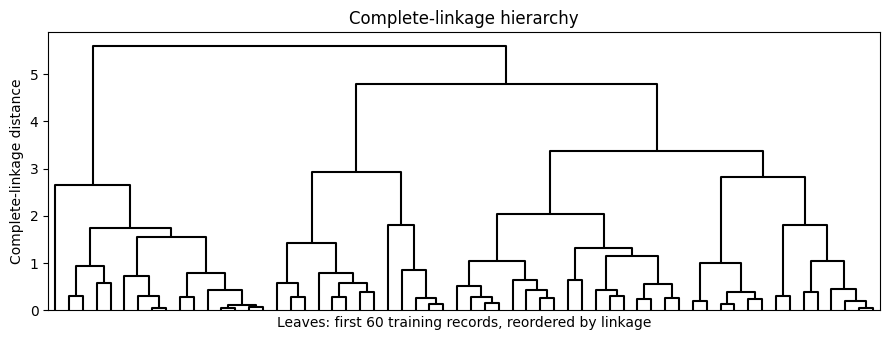

K-means above uses all training records; this tree uses the first 60.


In [27]:
_begin_stage(6)
# The hierarchy uses the first 60 TRAINING records in the same fitted PCA coordinates.
subset = Ztr[:60]
tree = linkage(subset, method="complete")
fig, ax = plt.subplots(figsize=(9, 3.5))
dendrogram(tree, no_labels=True, color_threshold=0, above_threshold_color="black", ax=ax)
ax.set_xlabel("Leaves: first 60 training records, reordered by linkage")
ax.set_ylabel("Complete-linkage distance")
ax.set_title("Complete-linkage hierarchy")
fig.tight_layout()
plt.show()
print("K-means above uses all training records; this tree uses the first 60.")

_finish_stage(6)


## Hierarchical clustering: 4 analysis points

Complete the labelled lines below in at most 40 words. Refer to supplied tables and figures; do not copy them.

**Merge-height observation from the supplied tree:** the hiearchy has different heights

**One method or sample-size reason for a difference from k-means:** 60 records can fail to represent true global distribution of all 432 readings.

## Individual engineering memo: 20 points, at most 250 words

Use the five headings below. Refer to the analysis and output labels instead of repeating calculations. Write your own recommendation. Decide which unusual records need measurement or operating-condition checks. Industrial and Aerospace flags are novelty screens, not verified faults.

### Decision: 3 points, maximum 40 words

Recommendation, operating condition and scope.

Your response:
Recommend targeted inspection of the operating logs corresponding to the three highest-scoring flagged anomalies (such as powerplant-02038) to confirm if extreme ambient combinations degraded output or represent sensor calibration issues.

### Evidence: 5 points, maximum 60 words

Two numbers with units and investigation references.

Your response:
Under Investigation 4, record powerplant-02038 yielded the highest score of 2.2909 (threshold 1.8199). In Investigation 5, this record registered an ambient temperature (AT) of 18.2°C and exhaust vacuum (V) of 52.72 cm Hg, which are significantly higher than its nearest group (Cluster 0) means of 12.06°C and 41.98 cm Hg.

### Interpretation: 5 points, maximum 60 words

Why the evidence supports the recommendation; separate calculation from inference.

Your response:
The K=3 model establishes that powerplant-02038 deviates significantly from typical cold-weather operation (Cluster 0). Statistically, its AT lies almost 2 standard deviations above the group mean. This mathematical outlier flags a highly atypical ambient operating regime, implying possible sensor drift or unique weather conditions that require validation.

### Limitations: 5 points, maximum 50 words

One important limitation and its consequence.

Your response:
K-means and PCA rely purely on statistical variance and coordinate distances without physical or thermodynamic laws. Consequently, a high anomaly score cannot distinguish between a harmless, rare weather event and an actual physical equipment malfunction.

### Next Action: 2 points, maximum 40 words

One independent verification and the result needed.

Your response:
Cross-reference the target net electrical output (MW) for powerplant-02038 with standard baseline plant operations at 18.2°C to determine if actual power output suffered during this event.

## Contribution and assistance

**My contribution and a check I performed (40 words maximum):** i contributed

**AI tool, help requested, where used, and how I checked it (60 words maximum, or None):** checked with class notes, help me with syntax errors and grammar.

**Other sources used (links or None):** none

The individual check is oral with the demonstrator, worth 10 points. Explain your own code and one result without partner or AI help. If working alone, describe a check of your own work.

Technical explanation /4: explain one result, the score-versus-fault distinction and which rows fitted preprocessing. Contribution/review /3: identify your work and a check you performed. Next step /3: justify an independent alert check.

## Micro-quiz: 8 minutes, 0 course marks

Answer three MCQs on Moodle when the demonstrator opens the activity. Work individually without AI or partner help.

## Save and submit

1. Run the export cell. Check the reported investigation count and file status.
2. Save the **executed notebook**, with outputs and written answers, and **results.json**.
3. In Colab, use **File > Download > Download .ipynb** for the notebook. Download results.json from the Files panel. A runtime reset can remove unsaved files.
4. Upload both files to Gradescope. Open the submitted notebook preview and confirm that your code, outputs and answers are present. Check the timestamp and file names.

Include the labelled analysis responses, five memo sections, contribution and AI disclosure. After a restart, run all cells from the top and upload the original ZIP when asked; then export again. Save the notebook regularly so typed answers are retained.

If unfinished, set `ALLOW_INCOMPLETE = True` in the export cell and submit the attempted work. It records missing investigations. Upload the current results.json, not a `.previous.json` backup.

In [28]:
# Set True only when deliberately submitting unfinished work.
ALLOW_INCOMPLETE = False #@param {type:"boolean"}
from miae383.lab_session import export_results
payload = export_results(globals(), [1, 2, 3, 4, 5, 6], ALLOW_INCOMPLETE)


Wrote results.json: complete; 6/6 investigations; 9 result fields.
Upload results.json and the executed notebook. Export does not check written answers or assign marks.
